# 03b NLP: what the similarity measures pick up (Person B)

Extra analyses on top of `03_nlp.ipynb`. That notebook builds and compares the similarity measures; this one asks
what they mean. Each section reuses a method from the course exercises:

| section | question | course |
|---|---|---|
| 1 | Which words make two films similar, and what do collaborating films share? | 6.2 §5 |
| 2 | Are a film's collaborators also its closest plots? | 6.2 §6 |
| 3 | Is the LDA model stable, and which number of topics is best? | 6.5 §1, §4 |
| 4 | What does plot space look like, coloured by genre and by community? | 7.2 §3, §5, §6 |
| 5 | Do the measures agree with people? Rated film pairs (the hand-labelled validation) | 7.10 §2, §3 |
| 6 | Files for Person C: topic shares per film and distinctive words | 6.5, 7.5 |

Needs `python nlp/scripts/build_similarity.py` to have been run. It only reads files, except section 5, which writes an
empty judgement sheet once.

In [1]:
import os
import sys
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))   # silences a joblib warning in t-SNE
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# The notebook runs in nlp/notebooks/; the project code is in nlp/scripts/
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import paths                    # every file location (nlp/scripts/paths.py)
import build_similarity as bs   # step 2 code: loading, TF-IDF, LDA

ids = bs.node_ids()                              # list of 1744 node_ids = the row order of every matrix
idx = {film: i for i, film in enumerate(ids)}    # node_id -> row number
n = len(ids)                                     # 1744 films

nodes = pd.read_csv(paths.FILMS_NODES, sep="\t", comment="#", quoting=3, keep_default_na=False)   # 1744 rows
edges = pd.read_csv(paths.FILMS_EDGES, sep="\t", comment="#", quoting=3, keep_default_na=False)   # 11,465 rows
assert list(nodes.node_id) == ids
title = dict(zip(nodes.node_id, nodes.name))           # node_id -> film title
genres = [set(g.split(",")) for g in nodes.genres]     # list of 1744 sets, e.g. {"Drama", "Sci-Fi"}

# The collaboration network: 1744 nodes, an edge when two films share a director or one of the 3 lead actors.
# Each edge stores its weight and the names of the shared people.
G = nx.Graph()
G.add_nodes_from(ids)
for e in edges.itertuples():
    G.add_edge(e.source, e.target, weight=e.weight, directors=e.director_names, actors=e.actor_names)

METHODS = ["tfidf", "lda", "minilm", "mpnet"]
# S[m]: the shared similarity matrix of method m (nlp/similarity/sim_*.npy), numpy array 1744 x 1744
S = {m: bs.load_shared(m) for m in METHODS}
clean = bs.load_clean()                          # plots_clean.tsv: 1744 rows

print(f"{n} films, {G.number_of_edges():,} edges, methods: {METHODS}")

1744 films, 11,465 edges, methods: ['tfidf', 'lda', 'minilm', 'mpnet']


## 1. Which words make two films similar? (6.2 §5)

The TF-IDF rows have length 1, so the cosine of two films is a sum over words: word *w* adds
`x_i[w] * x_j[w]`. Sorting those contributions shows which words a similarity comes from. This is the
`shared_terms` function from 6.2, here called `top_shared_words`.

In [2]:
# X: the TF-IDF matrix, sparse 1744 x 11,829 (films x words). Every row has length 1, so
#    cosine(film i, film j) = sum over all words w of X[i, w] * X[j, w]
_, X = bs.load("tfidf")
terms = np.array(paths.terms_file("tfidf").read_text(encoding="utf-8").split("\n"))   # 11,829 words; column w of X is terms[w]
assert len(terms) == X.shape[1]


def word_contributions(X_, i, j):
    """How much every word adds to the cosine of the films in rows i and j.

    Returns a dense array with one value per word (length = number of columns of X_). The values sum to
    the cosine.
    """
    return X_[i].multiply(X_[j]).toarray().ravel()


def top_shared_words(X_, vocab, i, j, k=8):
    """The k words that contribute most to cosine(i, j), with their share of the cosine, as one string."""
    contrib = word_contributions(X_, i, j)
    best = np.argsort(-contrib)[:k]
    return ", ".join(f"{vocab[w]} {contrib[w] / contrib.sum():.0%}" for w in best if contrib[w] > 0)


def shared_people(film_a, film_b):
    """The directors and actors two films share (stored on their edge), or "" if they are not linked."""
    edge = G.get_edge_data(film_a, film_b)
    if edge is None:
        return ""
    return " | ".join(names for names in (edge["directors"], edge["actors"]) if names)


def pair_table(film_pairs):
    """One row per (film A, film B): TF-IDF and mpnet similarity, shared people, top shared words."""
    rows = []
    for a, b in film_pairs:
        i, j = idx[a], idx[b]
        rows.append({"film A": title[a], "film B": title[b],
                     "TF-IDF": round(float(S["tfidf"][i, j]), 2),
                     "mpnet": round(float(S["mpnet"][i, j]), 2),
                     "shared people": shared_people(a, b),
                     "top shared words (share of the cosine)": top_shared_words(X, terms, i, j)})
    return pd.DataFrame(rows)

### 1.1 The most similar *linked* pairs

Films that share a director or actor **and** have very similar plots. Are these sequels in disguise, remakes, or
genuinely similar stories?

In [3]:
# linked: every edge of the network as a (film A, film B) pair, 11,465 pairs
linked = list(G.edges())
# The row numbers of the two ends of every edge: two int arrays of length 11,465
linked_a = np.array([idx[a] for a, _ in linked])
linked_b = np.array([idx[b] for _, b in linked])

linked_tfidf = S["tfidf"][linked_a, linked_b]     # TF-IDF similarity of every linked pair, 11,465 values
most_similar = np.argsort(-linked_tfidf)[:12]     # positions of the 12 most similar linked pairs
pair_table([linked[p] for p in most_similar])

,film A,film B,TF-IDF,mpnet,shared people,top shared words (share of the cosine)
0,Abraham Lincoln: Vampire Hunter,Dracula Untold,0.53,0.78,Dominic Cooper,"vampire 91%, silver 5%, soldier 1%, weakness 0..."
1,Assassin's Creed,Steve Jobs,0.41,0.60,Michael Fassbender,"apple 98%, ceo 1%, allow 0%, fake 0%, control ..."
2,City of Lies,Taken 3,0.28,0.86,Forest Whitaker,"lapd 78%, officer 5%, murder 4%, suit 2%, dete..."
3,La La Land,Whiplash,0.28,0.79,Damien Chazelle,"jazz 65%, band 11%, play 8%, music 2%, perform..."
4,Chappie,Real Steel,0.25,0.68,Hugh Jackman,"robot 84%, damage 4%, control 2%, destroy 1%, ..."
5,Insidious,The Conjuring,0.20,0.80,James Wan | Patrick Wilson,"spirit 37%, possess 35%, paranormal 6%, entity..."
6,Paranoia,The Laundromat,0.20,0.73,Gary Oldman,"company 85%, fraud 4%, corporation 3%, arrest ..."
7,2 Guns,Safe House,0.19,0.83,Denzel Washington,"cia 59%, intelligence 6%, interrogate 5%, repo..."
8,20th Century Women,Beginners,0.19,0.82,Mike Mills,"cancer 33%, relationship 8%, openly 5%, lung 4..."
9,The Second Best Exotic Marigold Hotel,Victoria and Abdul,0.19,0.64,Judi Dench,"india 86%, interest 5%, resent 3%, medical 1%,..."


### 1.2 The strongest collaborations: do they share a story?

The pairs with the highest edge weight (several shared people). A high weight with a low similarity means the same
team made very different films.

In [4]:
# The 12 edges with the highest weight (ties broken by the number of shared directors)
strongest = edges.sort_values(["weight", "shared_directors"], ascending=False).head(12)
pair_table(zip(strongest.source, strongest.target))

,film A,film B,TF-IDF,mpnet,shared people,top shared words (share of the cosine)
0,Southbound,V/H/S,0.13,0.85,Matt Bettinelli-Olpin|Tyler Gillett|David Bruc...,"creature 7%, car 6%, motel 5%, room 5%, man 3%..."
1,Summer of '84,Turbo Kid,0.01,0.56,François Simard|Anouk Whissell|Yoann-Karl Whis...,"sadistic 19%, trash 18%, parent 13%, explore 1..."
2,The Interview,This Is the End,0.02,0.67,Evan Goldberg|Seth Rogen | James Franco|Seth R...,"celebrity 18%, news 10%, party 8%, host 8%, pr..."
3,Focus,Whiskey Tango Foxtrot,0.03,0.53,Glenn Ficarra|John Requa | Margot Robbie,"sabotage 12%, dangerous 11%, access 9%, role 8..."
4,Office Christmas Party,The Switch,0.03,0.64,Josh Gordon|Will Speck | Jason Bateman,"party 29%, york 15%, city 10%, say 7%, result ..."
5,21 & Over,Bad Moms,0.05,0.80,Jon Lucas|Scott Moore,"domineering 49%, fun 9%, party 8%, apply 7%, i..."
6,21 & Over,Jexi,0.05,0.83,Jon Lucas|Scott Moore,"phone 23%, endure 11%, trick 10%, berate 7%, d..."
7,Bad Moms,Jexi,0.07,0.79,Jon Lucas|Scott Moore,"kid 19%, phone 17%, store 7%, coffee 6%, bad 6..."
8,Battle of the Sexes,Ruby Sparks,0.02,0.45,Jonathan Dayton|Valerie Faris,"woman 39%, original 10%, increasingly 9%, age ..."
9,Catfish,Nerve,0.04,0.61,Henry Joost|Ariel Schulman,"profile 34%, complete 9%, online 8%, account 7..."


### 1.3 What do collaborating films share, compared with random pairs?

Sum every word's contribution to the cosine over all 11,465 linked pairs, and over the same number of random
pairs. Words with a high ratio are what collaborators have in common more than chance. This is a first look at
*what kind of similarity* the network carries: genre words (e.g. "zombie"), settings, or professions.

In [5]:
# Random baseline: as many random film pairs as there are edges. Pairs of a film with itself are dropped.
rng = np.random.default_rng(0)
random_a = rng.integers(0, n, len(linked_a))
random_b = rng.integers(0, n, len(linked_a))
not_self = random_a != random_b
random_a, random_b = random_a[not_self], random_b[not_self]   # ~11,800 random pairs


def summed_contributions(X_, rows_a, rows_b):
    """Every word's contribution to the cosine, summed over many film pairs.

    X_[rows_a] and X_[rows_b] are both (number of pairs x number of words). Multiplying them element-wise
    gives each pair's word contributions; summing down the columns adds them up over all pairs.
    Returns one value per word.
    """
    return np.asarray(X_[rows_a].multiply(X_[rows_b]).sum(axis=0)).ravel()


linked_total = summed_contributions(X, linked_a, linked_b)          # 11,829 values, one per word
random_total = summed_contributions(X, random_a, random_b)
random_total = random_total * len(linked_a) / len(random_a)          # scale to the same number of pairs

print(f"mean TF-IDF cosine: linked {linked_total.sum() / len(linked_a):.4f}, "
      f"random {random_total.sum() / len(linked_a):.4f}")

words = pd.DataFrame({"word": terms, "linked pairs": linked_total, "random pairs": random_total})
# How over-represented a word is among collaborators. The small constant avoids dividing by zero for words
# that never contribute in random pairs.
words["ratio"] = (words["linked pairs"] + 1e-3) / (words["random pairs"] + 1e-3)

# Keep only words that carry a real share of the linked-pair similarity (the top 1% by summed contribution),
# then sort them by over-representation
carries_weight = words["linked pairs"] >= words["linked pairs"].quantile(0.99)
words[carries_weight].sort_values("ratio", ascending=False).head(25).round(3)

mean TF-IDF cosine: linked 0.0317, random 0.0282


,word,linked pairs,random pairs,ratio
1852,cia,1.172,0.345,3.388
6110,letter,0.839,0.363,2.311
200,affair,0.674,0.311,2.165
8169,prison,0.858,0.402,2.130
10504,team,1.726,0.823,2.096
6456,marry,0.855,0.431,1.980
2100,company,1.102,0.584,1.884
11530,war,0.722,0.392,1.842
4047,fbi,0.700,0.393,1.780
7653,pay,0.834,0.475,1.755


### 1.4 Removing the leftover names (the 6.5 capitalisation rule)

Before the sequels were removed from the dataset (1789 -> 1744 films), the strongest
linked-pair similarities came from character names that step 1 missed ("bishop", "chucky", "bughuul", "radners"):
sequels share both their crew and their characters, so these names inflated exactly the similarities that the
network comparison tests. With the sequels gone, these pairs no longer appear in sections 1.1 and 1.3, but a few
leftover names remain in single films. This section checks whether removing them still changes anything.

Exercise 6.5 used a simple rule: **a word that is capitalised in more than half of its uses is treated as a name**.
Here the rule is applied to the TF-IDF tokens, inside this notebook only. The pipeline and the shared `.npy` files
are unchanged. Capitalisation is counted in `text_masked`, the original text with the already-masked names removed.

The rule also removes place and organisation words ("york", "fbi"), which step 1 deliberately kept as story
content. So two variants are compared:
- **6.5 rule:** remove every word capitalised in more than half of its uses.
- **6.5 rule, rare words only:** remove such a word only if it occurs in at most 5 films. Franchise character names
  occur in 2-4 films; places and organisations usually occur in many more.

In [6]:
import re
from collections import Counter

# For every word (lowercased): how often it occurs, and how often it is written with a capital letter.
# The placeholder of the already-masked names ("PERSON") is skipped.
uses = Counter()
capitalised_uses = Counter()
for text in clean.text_masked:
    for word in re.findall(r"[A-Za-z]+", text.replace("PERSON", " ")):
        uses[word.lower()] += 1
        capitalised_uses[word.lower()] += word[0].isupper()          # True counts as 1

# The 6.5 rule: a word capitalised in more than half of its uses is treated as a name
proper_nouns = {w for w in uses if capitalised_uses[w] > uses[w] / 2}

# Document frequency of every TF-IDF token: in how many of the 1744 films it occurs
films_with_token = Counter(w for tokens in clean.tokens for w in set(tokens.split()))

RARE = 5   # "rare" = occurs in at most 5 films (franchise character names occur in 2-4)
words_to_drop = {
    "6.5 rule": {w for w in films_with_token if w in proper_nouns},
    "6.5 rule, rare words only": {w for w in films_with_token
                                  if w in proper_nouns and films_with_token[w] <= RARE},
}

for name, dropped in words_to_drop.items():
    print(f"{name}: removes {len(dropped):,} of {len(films_with_token):,} token types")

leftover_names = ["bishop", "chucky", "bughuul", "radners", "diper", "apple"]
print("\nthe leftover names from 1.1, caught?",
      {w: w in words_to_drop["6.5 rule, rare words only"] for w in leftover_names})

most_common_dropped = sorted(words_to_drop["6.5 rule"], key=lambda w: -films_with_token[w])[:30]
print("\nmost common words the full rule removes (films):",
      ", ".join(f"{w} {films_with_token[w]}" for w in most_common_dropped))

6.5 rule: removes 4,836 of 20,793 token types
6.5 rule, rare words only: removes 4,385 of 20,793 token types

the leftover names from 1.1, caught? {'bishop': False, 'chucky': True, 'bughuul': True, 'radners': True, 'diper': False, 'apple': False}

most common words the full rule removes (films): miss 282, york 258, american 217, los 149, angeles 145, united 138, states 115, fbi 103, captain 102, president 101, king 93, london 93, kid 92, red 88, university 87, earth 87, california 85, department 84, general 83, christmas 71, god 70, san 70, cia 70, paris 69, british 66, south 63, mexico 61, lord 60, north 59, america 58


In [7]:
def tfidf_without(drop_words):
    """Rebuild the TF-IDF matrix (same settings as sim_tfidf.npy) after removing some words from every plot.
    Returns (X, vocabulary): sparse 1744 x V and the V words."""
    texts = clean.tokens.map(lambda tokens: " ".join(w for w in tokens.split() if w not in drop_words))
    X_new, info = bs.build_tfidf(texts)
    return X_new, np.asarray(info["terms"])


# variants: name -> (TF-IDF matrix, its vocabulary)
variants = {"current (step 1 only)": (X, terms)}
for name, dropped in words_to_drop.items():
    variants[name] = tfidf_without(dropped)


def evaluate(X_v):
    """The checks of sections 1-2 for one TF-IDF matrix X_v (sparse 1744 x V, rows of length 1)."""
    S_v = (X_v @ X_v.T).toarray()                       # 1744 x 1744 cosine similarity
    linked_sims = S_v[linked_a, linked_b]               # similarity of every linked pair, 11,465 values

    # 1. How much of a top linked pair's cosine comes from its single biggest word (median over the top 50)
    top50 = np.argsort(-linked_sims)[:50]
    biggest_word_share = [X_v[linked_a[p]].multiply(X_v[linked_b[p]]).max() / linked_sims[p] for p in top50]

    # 2. The plot rank of every collaborator, with each edge seen from both ends (22,930 ranks).
    #    rank = number of films at least as similar, counting the film itself (as plot_rank in section 2)
    film = np.r_[linked_a, linked_b]
    collaborator = np.r_[linked_b, linked_a]
    ranks = np.array([(S_v[i] > S_v[i, j]).sum() for i, j in zip(film, collaborator)])

    # 3. Genre share of each film's 10 nearest films (as in 03_nlp.ipynb section 2.3)
    np.fill_diagonal(S_v, -1)                           # a film is not its own neighbour
    nearest10 = np.argsort(-S_v, axis=1)[:, :10]        # 1744 x 10
    genre_share = np.mean([bool(genres[i] & genres[j]) for i in range(n) for j in nearest10[i]])

    return {"mean cosine linked / random": round(linked_sims.mean() / S_v[random_a, random_b].mean(), 3),
            "top-50 linked pairs: share from one word": f"{np.median(biggest_word_share):.0%}",
            "median rank of collaborators": int(np.median(ranks)),
            "collaborators in top 50": f"{(ranks <= 50).mean():.1%}",
            "top-10 neighbours sharing a genre": round(genre_share, 3)}


pd.DataFrame({name: evaluate(X_v) for name, (X_v, _) in variants.items()}).T

,mean cosine linked / random,top-50 linked pairs: share from one word,median rank of collaborators,collaborators in top 50,top-10 neighbours sharing a genre
current (step 1 only),1.125,52%,741,4.1%,0.803
6.5 rule,1.119,45%,737,4.0%,0.811
"6.5 rule, rare words only",1.127,49%,733,4.0%,0.806


**Reading the table.**
- **One word dominating.** If removing the names works, the strongest linked pairs should no longer rest on a single
  word.
- **Network signal.** The linked/random ratio and the collaborator ranks are the network signal. If they drop, part of
  the apparent link between collaboration and plot was shared character names.
- **Genre.** The genre check shows whether the plot signal itself survives.

The most similar linked pairs after the rare-words filter:

In [8]:
X_rare, terms_rare = variants["6.5 rule, rare words only"]

# TF-IDF similarity of every linked pair after the filter (11,465 values): the dot product of the two rows
linked_after = np.array([X_rare[i].multiply(X_rare[j]).sum() for i, j in zip(linked_a, linked_b)])

rows = []
for p in np.argsort(-linked_after)[:12]:          # the 12 most similar linked pairs after the filter
    i, j = linked_a[p], linked_b[p]
    rows.append({"film A": title[ids[i]], "film B": title[ids[j]],
                 "before": round(float(S["tfidf"][i, j]), 2),
                 "after": round(float(linked_after[p]), 2),
                 "top shared words": top_shared_words(X_rare, terms_rare, i, j, k=6)})
pd.DataFrame(rows)

,film A,film B,before,after,top shared words
0,Abraham Lincoln: Vampire Hunter,Dracula Untold,0.53,0.59,"vampire 91%, silver 5%, soldier 1%, weakness 0..."
1,Assassin's Creed,Steve Jobs,0.41,0.48,"apple 98%, ceo 1%, allow 0%, fake 0%, control ..."
2,City of Lies,Taken 3,0.28,0.28,"lapd 78%, officer 5%, murder 4%, suit 2%, dete..."
3,La La Land,Whiplash,0.28,0.28,"jazz 65%, band 11%, play 8%, music 2%, perform..."
4,Chappie,Real Steel,0.25,0.26,"robot 84%, damage 4%, control 2%, destroy 1%, ..."
5,Beirut,The Report,0.18,0.23,"cia 83%, report 4%, release 2%, official 1%, o..."
6,Blair Witch,V/H/S,0.18,0.23,"tape 18%, camcorder 17%, entity 7%, group 4%, ..."
7,Kidnap,The Call,0.17,0.23,"kidnapper 45%, car 6%, parking 5%, police 3%, ..."
8,Carrie,Laggies,0.13,0.22,"prom 72%, school 5%, door 2%, week 2%, dress 2..."
9,Selma,The Butler,0.10,0.22,"marcher 16%, white 15%, president 13%, activis..."


## 2. Are a film's collaborators also its closest plots? (6.2 §6)

In 6.2 we compared three definitions of "neighbour" for one Marvel character. Here: a film's **network
neighbours** (shared director/actor) against its **plot neighbours** under each method. The rank says where a
collaborator lands among the film's 1,743 others when sorted by plot similarity (1 = closest plot).

This is descriptive. The statistical test with null models is Person A's (SQ1).

In [9]:
def plot_rank(i, j, m):
    """Where film j lands among film i's 1,743 other films when sorted by plot similarity (1 = closest).

    Counts the films that are more similar to i than j is. Film i itself (similarity 1) is always among
    them, which turns "number of films ahead of j" into a rank that starts at 1.
    """
    return int((S[m][i] > S[m][i, j]).sum())


def collaborators_table(film, k=10):
    """The k strongest collaborators of a film (by edge weight), with their plot rank under every method."""
    i = idx[film]
    strongest_first = sorted(G[film].items(), key=lambda item: -item[1]["weight"])[:k]   # [(neighbour, edge), ...]
    rows = []
    for neighbour, edge in strongest_first:
        row = {"collaborator": title[neighbour], "weight": edge["weight"],
               "shared people": shared_people(film, neighbour)}
        for m in METHODS:
            row[f"rank {m}"] = plot_rank(i, idx[neighbour], m)
        rows.append(row)
    return pd.DataFrame(rows)


def closest_plots_table(film, m="mpnet", k=10):
    """The k films with the most similar plot under method m, and whether each is linked to the film."""
    i = idx[film]
    nearest = [j for j in np.argsort(-S[m][i]) if j != i][:k]     # row numbers, most similar first
    return pd.DataFrame({f"closest plots ({m})": [title[ids[j]] for j in nearest],
                         "cosine": [round(float(S[m][i, j]), 2) for j in nearest],
                         "linked?": ["yes" if G.has_edge(film, ids[j]) else "" for j in nearest]})


for film in ["Inception", "La_La_Land"]:
    print(f"{title[film]}: {G.degree(film)} network neighbours")
    display(collaborators_table(film))
    display(closest_plots_table(film))

Inception: 24 network neighbours


,collaborator,weight,shared people,rank tfidf,rank lda,rank minilm,rank mpnet
0,Dunkirk,3.0,Christopher Nolan,1113,396,1440,1314
1,Interstellar,3.0,Christopher Nolan,480,241,422,824
2,The Dark Knight Rises,3.0,Christopher Nolan,594,202,97,195
3,50/50,1.0,Joseph Gordon-Levitt,773,1692,1227,1413
4,7500,1.0,Joseph Gordon-Levitt,623,605,941,1375
5,Django Unchained,1.0,Leonardo DiCaprio,1419,213,1262,1089
6,Don Jon,1.0,Joseph Gordon-Levitt,1400,975,1327,1008
7,Flatliners,1.0,Elliot Page,450,381,12,1
8,Hesher,1.0,Joseph Gordon-Levitt,278,976,1007,1114
9,Into the Forest,1.0,Elliot Page,906,1036,807,1468


,closest plots (mpnet),cosine,linked?
0,Flatliners,0.75,yes
1,2:22,0.75,
2,A Nightmare on Elm Street,0.73,
3,Chronicle,0.73,
4,The 9th Life of Louis Drax,0.73,
5,Lights Out,0.73,
6,Shut In,0.73,
7,Get Out,0.73,
8,Amityville: The Awakening,0.73,
9,Dream House,0.72,


La La Land: 28 network neighbours


,collaborator,weight,shared people,rank tfidf,rank lda,rank minilm,rank mpnet
0,First Man,4.0,Damien Chazelle | Ryan Gosling,1402,1017,831,1275
1,Whiplash,3.0,Damien Chazelle,1,17,29,9
2,Gangster Squad,2.0,Emma Stone|Ryan Gosling,1273,1233,1196,1223
3,Lost River,2.0,,1485,1160,1029,1082
4,All Good Things,1.0,Ryan Gosling,861,306,445,159
5,Aloha,1.0,Emma Stone,387,579,407,720
6,Battle of the Sexes,1.0,Emma Stone,1043,1083,1533,1575
7,Blade Runner 2049,1.0,Ryan Gosling,1009,1564,1304,1486
8,Blue Valentine,1.0,Ryan Gosling,541,245,261,128
9,"Crazy, Stupid, Love.",1.0,Ryan Gosling,146,88,139,154


,closest plots (mpnet),cosine,linked?
0,Begin Again,0.82,
1,Breathe In,0.81,
2,Beyond the Lights,0.81,
3,We Are Your Friends,0.81,
4,A Rainy Day in New York,0.81,
5,Rocketman,0.80,
6,I Can Only Imagine,0.80,
7,Judy,0.80,
8,Whiplash,0.79,yes
9,Forever My Girl,0.79,


### 2.1 All films at once

For every film with at least one network neighbour: the median plot rank of its collaborators, and the share of
its collaborators that fall in its 10 or 50 closest plots. If collaboration had nothing to do with plot, the median
rank would be about 871 (the middle of 1,743), and the shares would be 10/1743 = 0.6% and 50/1743 = 2.9%.

In [10]:
rows = []
for m in METHODS:
    # Every edge seen from both ends: the rank of B among A's films, and of A among B's films (22,930 ranks)
    ranks = np.array([plot_rank(i, j, m) for i, j in zip(linked_a, linked_b)] +
                     [plot_rank(j, i, m) for i, j in zip(linked_a, linked_b)])
    rows.append({"method": m,
                 "median rank of collaborators": int(np.median(ranks)),
                 "in top 10": f"{(ranks <= 10).mean():.1%}",
                 "in top 50": f"{(ranks <= 50).mean():.1%}"})

# What to expect if collaboration had nothing to do with plot: ranks spread evenly over 1 .. n-1
others = n - 1
rows.append({"method": "chance", "median rank of collaborators": others // 2,
             "in top 10": f"{10 / others:.1%}", "in top 50": f"{50 / others:.1%}"})
pd.DataFrame(rows)

,method,median rank of collaborators,in top 10,in top 50
0,tfidf,741,0.9%,4.1%
1,lda,738,0.9%,4.6%
2,minilm,730,1.1%,5.1%
3,mpnet,734,1.1%,5.2%
4,chance,871,0.6%,2.9%


## 3. LDA: how many topics, and is the model stable? (6.5 §1, §4)

Two checks:
- **Choosing K by topic coherence** (as in the task division). For each K, fit LDA and compute c_v coherence over
  each topic's 10 top words. c_v (Röder et al. 2015) measures how often a topic's top words occur near each other in
  the plots. Higher is better.
- **Stability** (6.5 §4). Refit with another seed and with more topics. Then check:
  - Do the topics come back? (cosine between topic word distributions)
  - Do films keep their dominant topic? (adjusted Rand index)
  - Does the LDA similarity matrix itself stay the same? (what A and C actually use)

All fits use the settings of `build_similarity.py` (`bs.fit_lda`). The sweep takes about 3 minutes.

K,5,10,15,20,25,30,40,50
c_v coherence,0.461,0.464,0.476,0.471,0.454,0.429,0.416,0.405
perplexity,2253.000,2271.000,2328.000,2357.000,2404.000,2487.000,2569.000,2678.000


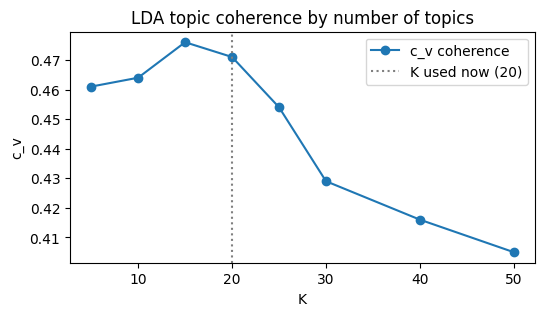

In [11]:
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity

texts = [tokens.split() for tokens in clean.tokens]    # list of 1744 token lists (gensim wants lists of words)
dictionary = Dictionary(texts)                          # gensim's mapping word <-> id


def topic_top_words(model, topic, k=10):
    """The k most probable words of one topic. model: a dict returned by bs.fit_lda."""
    return [model["vocab"][w] for w in np.argsort(-model["phi"][topic])[:k]]


def coherence(model):
    """Average c_v coherence of all topics of a model, computed from each topic's 10 top words."""
    n_topics = model["phi"].shape[0]
    top_words = [topic_top_words(model, t) for t in range(n_topics)]
    cm = CoherenceModel(topics=top_words, texts=texts, dictionary=dictionary, coherence="c_v", processes=1)
    return cm.get_coherence()


K_VALUES = [5, 10, 15, 20, 25, 30, 40, 50]
fits = {}      # K -> fitted model: dict with theta (1744 x K), phi (K x V), vocab, perplexity
rows = []
for k in K_VALUES:
    fits[k] = bs.fit_lda(clean.tokens, k, seed=0)
    rows.append({"K": k, "c_v coherence": round(coherence(fits[k]), 3),
                 "perplexity": round(fits[k]["perplexity"])})
sweep = pd.DataFrame(rows).set_index("K")
display(sweep.T)

ax = sweep["c_v coherence"].plot(marker="o", figsize=(6, 3), title="LDA topic coherence by number of topics")
ax.axvline(bs.LDA_K, color="grey", ls=":", label=f"K used now ({bs.LDA_K})")
ax.set_ylabel("c_v")
ax.legend()
plt.show()

**Reading the sweep.** Coherence is noisy from one fit to the next, so look for a plateau rather than the single
highest point. Perplexity usually keeps falling as K grows, which is why it is not used to choose K.

**Decision.** Coherence peaks at K = 15, with a plateau from 5 to 20 topics and a drop above 25. We keep
**K = 20**: it lies on the plateau (c_v within about 0.01 of the best), and it gives finer topics for describing
communities. To rebuild with another K: `python nlp/scripts/build_similarity.py --only lda --lda-k 15`.


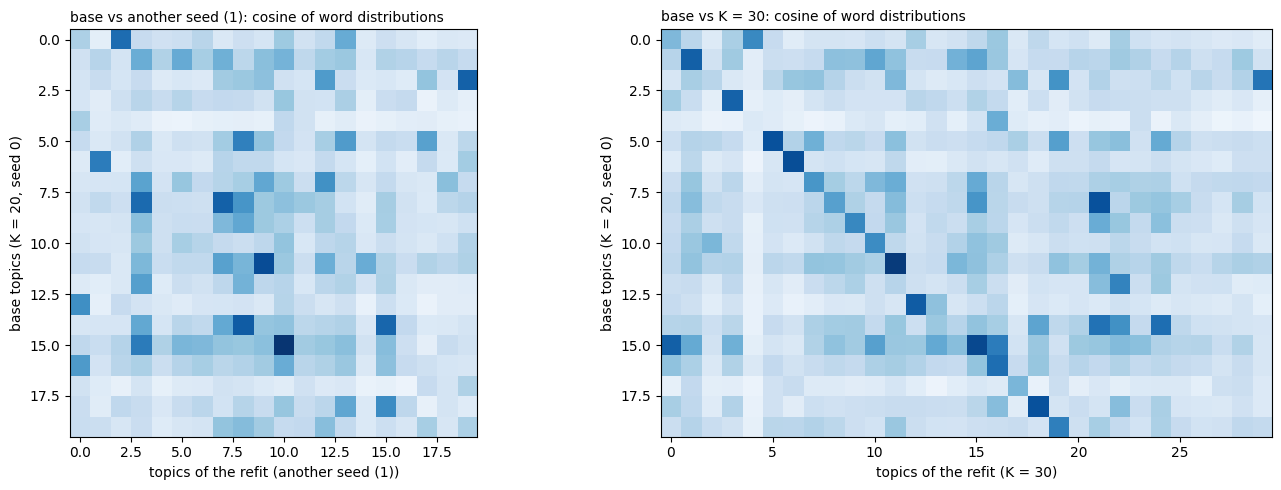

,refit,base topics with a match (cos > 0.7),dominant topic agreement (ARI),similarity matrix (Spearman)
0,another seed (1),7 of 20,0.46,0.65
1,K = 30,12 of 20,0.28,0.61


In [12]:
base = fits[bs.LDA_K]                                     # the model used in the pipeline (K = 20, seed 0)
refits = {"another seed (1)": bs.fit_lda(clean.tokens, bs.LDA_K, seed=1),
          "K = 30": fits[30]}

# Do the topics come back? Cosine between every base topic and every refit topic (their word distributions)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, refit) in zip(axes, refits.items()):
    topic_match = cosine_similarity(base["phi"], refit["phi"])    # 20 x (number of refit topics)
    ax.imshow(topic_match, cmap="Blues", vmin=0, vmax=1)
    ax.set_xlabel(f"topics of the refit ({name})")
    ax.set_ylabel(f"base topics (K = {bs.LDA_K}, seed 0)")
    ax.set_title(f"base vs {name}: cosine of word distributions", loc="left", fontsize=10)
plt.tight_layout()
plt.show()


def dominant_topic(model):
    """Each film's strongest topic: int array of length 1744."""
    return model["theta"].argmax(axis=1)


def lda_similarity(model):
    """1744 x 1744 cosine similarity of the films' topic mixtures (what sim_lda.npy holds)."""
    theta = model["theta"] / np.linalg.norm(model["theta"], axis=1, keepdims=True)
    return theta @ theta.T


# A random sample of 300,000 of the 1.6M film pairs is enough for a correlation
pair_rows, pair_cols = np.triu_indices(n, 1)
sample = np.random.default_rng(0).choice(len(pair_rows), 300_000, replace=False)
pair_rows, pair_cols = pair_rows[sample], pair_cols[sample]
base_sim = lda_similarity(base)[pair_rows, pair_cols]      # 300,000 values

rows = []
for name, refit in refits.items():
    topic_match = cosine_similarity(base["phi"], refit["phi"])
    refit_sim = lda_similarity(refit)[pair_rows, pair_cols]
    rows.append({"refit": name,
                 "base topics with a match (cos > 0.7)": f"{(topic_match.max(axis=1) > 0.7).sum()} of {bs.LDA_K}",
                 "dominant topic agreement (ARI)": round(adjusted_rand_score(dominant_topic(base), dominant_topic(refit)), 2),
                 "similarity matrix (Spearman)": round(spearmanr(base_sim, refit_sim)[0], 2)})
pd.DataFrame(rows)

For comparison: in `03_nlp.ipynb` §2.2, TF-IDF and the encoders correlate with each other at 0.6-0.9. If the LDA
similarity changes a lot between two seeds of the same model, its pair-level similarities should be interpreted with
care, and its topics are more useful as descriptions (topic shares per community) than as a similarity measure.

## 4. A map of plot space (7.2 §3, §5, §6)

Project the mpnet film vectors to 2D:
- **PCA** keeps the large-scale directions.
- **t-SNE** keeps local neighbourhoods.

Colour the same coordinates by genre, then by network community. If collaboration communities form regions on the
map, films made by the same people tell similar stories.

**Genre colour.** IMDb lists up to three genres per film, alphabetically, so "the first genre" is meaningless.
Each film gets the first of these that it has: Horror, Sci-Fi, Romance, Comedy, Crime, Action. Otherwise it is
"other" (mostly drama).

C:\Users\slmwz\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\slmwz\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^

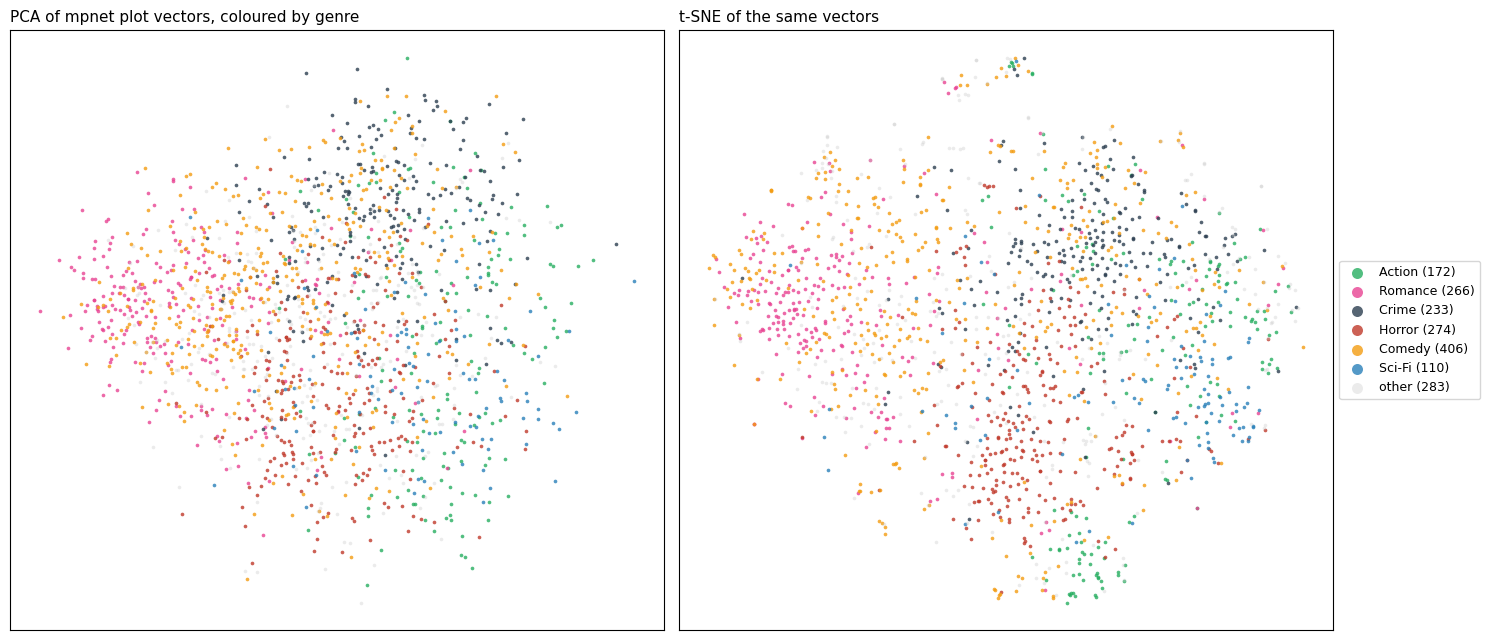

In [13]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# E: the mpnet film vectors, 1744 x 768, rows of length 1
_, E = bs.load("mpnet")
pca_xy = PCA(n_components=2, random_state=0).fit_transform(E)            # 1744 x 2
tsne_xy = TSNE(n_components=2, metric="cosine", init="pca", perplexity=30,
               random_state=0).fit_transform(E)                           # 1744 x 2

# One genre label per film: the first genre of this list that the film has, otherwise "other"
GENRE_ORDER = ["Horror", "Sci-Fi", "Romance", "Comedy", "Crime", "Action"]
genre_label = np.array([next((g for g in GENRE_ORDER if g in film_genres), "other") for film_genres in genres])
GENRE_COLORS = {"Horror": "#c0392b", "Sci-Fi": "#2980b9", "Romance": "#e84393", "Comedy": "#f39c12",
                "Crime": "#2c3e50", "Action": "#27ae60", "other": "#c8c8c8"}

GREY_GROUPS = ("other", "rest")


def scatter(ax, xy, labels, colors, title_text):
    """Scatter plot of 2D coordinates xy (1744 x 2) with one colour per label (labels: 1744 strings).
    Grey groups are drawn first, so the coloured groups lie on top."""
    groups = sorted(set(labels), key=lambda label: label in GREY_GROUPS)
    for label in groups:
        in_group = labels == label
        is_grey = label in GREY_GROUPS
        ax.scatter(xy[in_group, 0], xy[in_group, 1], s=7, c=colors.get(label, "#c8c8c8"),
                   label=f"{label} ({in_group.sum()})", alpha=0.35 if is_grey else 0.8, linewidths=0)
    ax.set_title(title_text, loc="left", fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
scatter(axes[0], pca_xy, genre_label, GENRE_COLORS, "PCA of mpnet plot vectors, coloured by genre")
scatter(axes[1], tsne_xy, genre_label, GENRE_COLORS, "t-SNE of the same vectors")
axes[1].legend(markerscale=3, fontsize=9, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 4.1 Can the map be trusted? Map neighbours vs. cosine neighbours (7.2 §5)

t-SNE distorts distances. For each film, compare its 10 nearest films on the map with its 10 nearest films in
the full 768-dimensional space. Only regions where these agree should be read as "these plots are similar".

In [14]:
from sklearn.neighbors import NearestNeighbors

# Each film's 10 nearest films in the full 768-dimensional space. E @ E.T is the 1744 x 1744 cosine matrix;
# column 0 of the sorted order is the film itself, so columns 1-10 are kept.
cosine_nn = np.argsort(-(E @ E.T), axis=1)[:, 1:11]                       # 1744 x 10

for name, xy in [("PCA", pca_xy), ("t-SNE", tsne_xy)]:
    # Each film's 10 nearest films on the 2D map (Euclidean distance), again skipping the film itself
    map_nn = NearestNeighbors(n_neighbors=11).fit(xy).kneighbors(xy, return_distance=False)[:, 1:]   # 1744 x 10
    overlap = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(cosine_nn, map_nn)])
    print(f"{name:<6} share of the 10 map neighbours that are also among the 10 cosine neighbours: {overlap:.0%}")

PCA    share of the 10 map neighbours that are also among the 10 cosine neighbours: 5%
t-SNE  share of the 10 map neighbours that are also among the 10 cosine neighbours: 29%


### 4.2 Coloured by network community (7.2 §6)

The communities are Person C's (`communities/partitions.tsv`). Until that file exists, this cell uses a
**placeholder**: one weighted Louvain run on the collaboration network (seed 0). The 8 largest communities are
coloured, the rest are grey. Replace it once C's partition is in.

PLACEHOLDER: communities/partitions.tsv not found, using one Louvain run (seed 0)


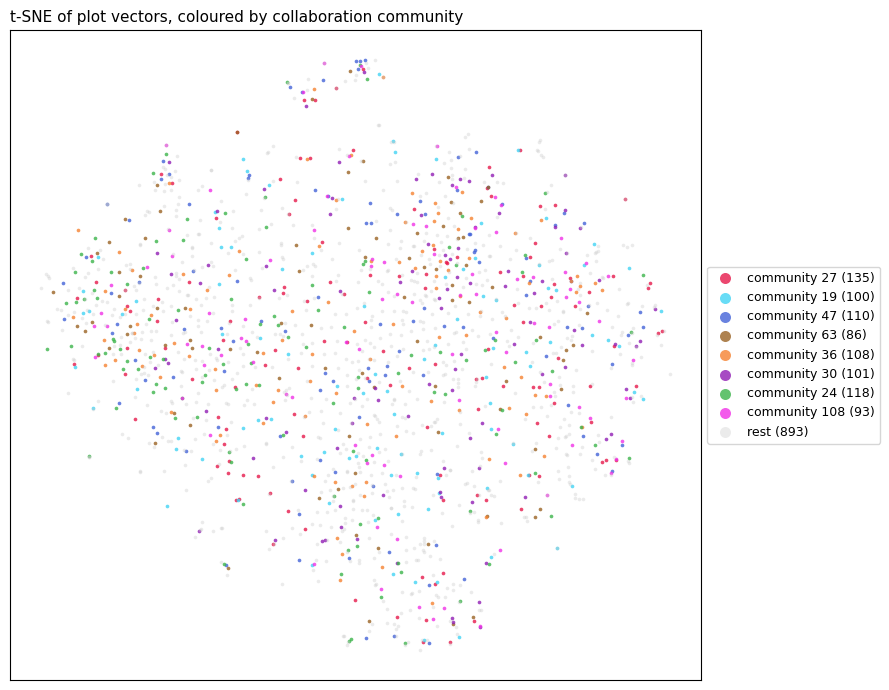

community  27 (135 films): Drama 27%, Action 10%, Crime 9%, Comedy 8%
community  24 (118 films): Drama 23%, Comedy 21%, Romance 11%, Horror 6%
community  47 (110 films): Drama 23%, Comedy 11%, Action 11%, Thriller 9%
community  36 (108 films): Drama 22%, Comedy 14%, Action 12%, Crime 11%
community  30 (101 films): Drama 22%, Action 17%, Crime 10%, Thriller 10%
community  19 (100 films): Drama 22%, Comedy 13%, Action 11%, Crime 8%
community 108 ( 93 films): Drama 22%, Action 13%, Comedy 9%, Thriller 9%
community  63 ( 86 films): Comedy 19%, Drama 15%, Action 14%, Crime 10%


In [15]:
# community: dict node_id -> community number
if paths.PARTITIONS.exists():
    partitions = pd.read_csv(paths.PARTITIONS, sep="\t", comment="#")
    print("using", paths.PARTITIONS, "- first scheme and seed in the file")
    first = (partitions.scheme == partitions.scheme.iloc[0]) & (partitions.seed == partitions.seed.iloc[0])
    community = dict(zip(partitions[first].node_id, partitions[first].community))
else:
    print("PLACEHOLDER: communities/partitions.tsv not found, using one Louvain run (seed 0)")
    communities = nx.community.louvain_communities(G, weight="weight", seed=0)   # list of sets of films
    community = {film: c for c, members in enumerate(communities) for film in members}

# Colour the 8 largest communities; all others are grey ("rest")
largest = list(pd.Series(community).value_counts().index[:8])
community_label = np.array([f"community {community[f]}" if community.get(f) in largest else "rest" for f in ids])
PALETTE = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#42d4f4", "#f032e6", "#9a6324"]
COMMUNITY_COLORS = {f"community {c}": colour for c, colour in zip(largest, PALETTE)}

fig, ax = plt.subplots(figsize=(9, 7))
scatter(ax, tsne_xy, community_label, COMMUNITY_COLORS, "t-SNE of plot vectors, coloured by collaboration community")
ax.legend(markerscale=3, fontsize=9, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

# A first description of the large communities: their most common genres
for c in largest:
    members = [i for i, film in enumerate(ids) if community.get(film) == c]     # row numbers
    genre_counts = pd.Series([g for i in members for g in genres[i]]).value_counts(normalize=True).head(4)
    print(f"community {c:>3} ({len(members):>3} films): "
          + ", ".join(f"{g} {share:.0%}" for g, share in genre_counts.items()))

## 5. Hand-labelled validation: rated film pairs (key check, 7.10 §2, §3)

One rating task answers two questions:
1. **Does each similarity measure agree with people?** Spearman correlation between each method's cosine and the
   human rating, over pairs spread from very similar to unrelated (the task division's "~60 pairs stratified by
   similarity").
2. **Are each method's nearest neighbours really similar films?** The mean rating of each method's 2 nearest films
   (as in 7.10, where a few queries were judged by hand).

**How the pairs are chosen.** Pairs are grouped around 6 query films, so a rater reads a query once and then compares
about 10 films with it. The queries are fixed by a rule, not by the results: 6 of the 25 most-voted films, one per
genre (sci-fi, western, crime, action, mystery, music drama). For each query the sheet holds
- the **2 nearest films of every method** (pooled, duplicates removed): these answer question 2, and they are the
  high end of the similarity range for question 1;
- **4 films drawn at random from lower similarity bands**, by the query's average percentile over the 4 methods:
  70-95%, 40-70%, 10-40% and 0-10%. They fill the middle and the low end, so the Spearman correlation covers the
  whole range.

The films of a query are shuffled, so a rater cannot tell which method (or band) a film came from. That gives
about 60 pairs.

**How to rate.** `pair_ratings_plots.md` (next to the sheet) gives the start of every Wikipedia plot, numbered as
in the sheet; you do not need to know the films. Write a rating from 1 to 5 in your own column of
`pair_ratings.tsv`, without looking at the others' columns:

| rating | meaning |
|---|---|
| 1 | unrelated plots |
| 2 | only a loose link: same broad genre or mood, nothing else in common |
| 3 | one clear shared element: setting, profession, type of conflict or theme |
| 4 | similar premise or central conflict |
| 5 | almost the same kind of story |

Edit the sheet in a text editor, not Excel. Then rerun the scoring cell below.

In [16]:
import re
import urllib.parse
import zipfile

from scipy.stats import rankdata

# The 6 query films: from the 25 most-voted films, one per genre. Fixed before looking at any results.
QUERIES = ["Inception", "Django_Unchained", "The_Wolf_of_Wall_Street_(2013_film)", "Mad_Max:_Fury_Road",
           "Gone_Girl_(film)", "Whiplash_(2014_film)"]
K = 2                                            # each method's 2 nearest films are rated
BANDS = [(70, 95), (40, 70), (10, 40), (0, 10)]  # percentile bands of the extra random films (one film each)
RATERS = ["rater_1", "rater_2", "rater_3"]
SUMMARY_WORDS = 120                              # length of the plot summaries shown to raters
url = dict(zip(nodes.node_id, nodes.url))       # node_id -> Wikipedia URL


def nearest_films(film, m, k=K):
    """The node_ids of the k films with the most similar plot under method m."""
    i = idx[film]
    return [ids[j] for j in np.argsort(-S[m][i]) if j != i][:k]


def average_percentile(film):
    """For every film: its similarity to `film` as a percentile (0-100), averaged over the 4 methods.
    Returns an array of length n; a high value means all methods find the plot similar."""
    i = idx[film]
    return np.mean([rankdata(S[m][i]) / n * 100 for m in METHODS], axis=0)


def plot_summary(plot, max_words=SUMMARY_WORDS):
    """The first whole sentences of a plot, about max_words words."""
    summary = []
    for sentence in re.split(r"(?<=[.!?])\s+", plot):
        summary.append(sentence)
        if len(" ".join(summary).split()) >= max_words:
            break
    return " ".join(summary)


if paths.PAIR_RATINGS.exists():                  # never overwrite ratings
    print(f"{paths.PAIR_RATINGS.relative_to(paths.ROOT)} exists, not overwritten")
else:
    # plots: node_id -> original plot text (names not masked, so it is easy to read)
    with zipfile.ZipFile(paths.PLOTS_ZIP) as z:
        plots = {urllib.parse.unquote(Path(name).stem): z.read(name).decode("utf-8")
                 for name in z.namelist() if name.endswith(".txt") and not name.endswith("README.txt")}

    rng = np.random.default_rng(42)
    rows = []
    sheet_md = ["# Plot summaries for pair_ratings.tsv", "",
                f"The first ~{SUMMARY_WORDS} words of each Wikipedia plot. Rows are numbered as in the sheet.",
                "Rate each row in `pair_ratings.tsv` from 1 (unrelated) to 5 (almost the same kind of story).", ""]
    for query in QUERIES:
        # 1. every method's K nearest films, pooled
        candidates = sorted({film for m in METHODS for film in nearest_films(query, m)})
        # 2. one random film from each lower similarity band (not the query, not already chosen)
        pct = average_percentile(query)
        for low, high in BANDS:
            band = [ids[j] for j in np.flatnonzero((pct > low) & (pct <= high))
                    if ids[j] != query and ids[j] not in candidates]
            candidates.append(str(rng.choice(band)))
        # 3. shuffle, so a rater cannot tell where a film came from
        sheet_md += ["---", "", f"## Query: {title[query]}", "", plot_summary(plots[query]), ""]
        for candidate in rng.permutation(candidates):
            rows.append({"row": len(rows) + 1, "query": query, "candidate": candidate,
                         "query_title": title[query], "candidate_title": title[candidate],
                         "candidate_url": url[candidate], **{r: "" for r in RATERS}})
            sheet_md += [f"**Row {len(rows)}: {title[candidate]}** ([Wikipedia]({url[candidate]}))", "",
                         plot_summary(plots[candidate]), ""]
    paths.VALIDATION.mkdir(exist_ok=True)
    pd.DataFrame(rows).to_csv(paths.PAIR_RATINGS, sep="\t", index=False)
    paths.PAIR_PLOTS.write_text("\n".join(sheet_md), encoding="utf-8")
    print(f"wrote {paths.PAIR_RATINGS.relative_to(paths.ROOT)}: {len(rows)} pairs to rate "
          f"({len(rows) / len(QUERIES):.1f} per query)")
    print(f"wrote {paths.PAIR_PLOTS.relative_to(paths.ROOT)}: the plot summaries for the raters")

wrote nlp\validation\pair_ratings.tsv: 63 pairs to rate (10.5 per query)
wrote nlp\validation\pair_ratings_plots.md: the plot summaries for the raters


### 5.1 Scoring

Run after rating. Uses every rater column that is completely filled in.
- **Agreement between raters:** Spearman correlation and quadratic-weighted Cohen's kappa for every pair of
  raters. The weighted kappa counts a 4 vs 5 disagreement as smaller than a 1 vs 5 one.
- **Measure vs. people:** Spearman correlation between each method's cosine and the mean rating, over all pairs,
  with a 95% bootstrap interval (resampling pairs). This is the data for Fig. 2.
- **Nearest neighbours:** the mean rating of each method's 2 nearest films over the 6 queries, and the share
  rated 4 or 5 (similar premise or better).

In [17]:
from sklearn.metrics import cohen_kappa_score

sheet = pd.read_csv(paths.PAIR_RATINGS, sep="\t", dtype=str, keep_default_na=False)
complete_raters = [r for r in RATERS if (sheet[r].str.strip() != "").all()]   # columns with no empty cell

if not complete_raters:
    print("No rater column is complete yet: fill in rater_1 (and others), then rerun this cell.")
else:
    for r in complete_raters:
        sheet[r] = sheet[r].astype(int)
    sheet["rating"] = sheet[complete_raters].mean(axis=1)        # mean rating of the pair, 1-5
    print("raters used:", complete_raters, f"| {len(sheet)} pairs")

    # Agreement between raters
    for i, a in enumerate(complete_raters):
        for b in complete_raters[i + 1:]:
            print(f"{a} vs {b}: Spearman {spearmanr(sheet[a], sheet[b])[0]:.2f}, "
                  f"weighted kappa {cohen_kappa_score(sheet[a], sheet[b], weights='quadratic'):.2f}")

    # Each method's cosine for every rated pair: dict method -> array of len(sheet)
    rated_sims = {m: np.array([S[m][idx[q], idx[c]] for q, c in zip(sheet["query"], sheet.candidate)])
                  for m in METHODS}

    # Measure vs. people: Spearman with a bootstrap interval (resample the pairs 2000 times)
    rng = np.random.default_rng(0)
    boot = rng.integers(0, len(sheet), size=(2000, len(sheet)))  # 2000 x n_pairs row indices
    ratings = sheet.rating.to_numpy()
    rows = []
    for m in METHODS:
        rho = spearmanr(rated_sims[m], ratings)[0]
        boot_rho = [spearmanr(rated_sims[m][b], ratings[b])[0] for b in boot]
        low, high = np.nanpercentile(boot_rho, [2.5, 97.5])
        rows.append({"method": m, "Spearman with ratings": round(rho, 2), "95% interval": f"{low:.2f} to {high:.2f}"})
    display(pd.DataFrame(rows).set_index("method"))

    # Nearest neighbours: every method's K nearest films are in the sheet by construction
    # (a KeyError means the sheet was built from other matrices, see the caveat below)
    rating_of = {(q, c): v for q, c, v in zip(sheet["query"], sheet.candidate, sheet.rating)}
    rows = []
    for m in METHODS:
        neighbour_ratings = np.array([rating_of[(q, c)] for q in QUERIES for c in nearest_films(q, m)])  # 6 x K
        rows.append({"method": m, f"mean rating of the {K} nearest films": round(neighbour_ratings.mean(), 2),
                     "share rated 4 or 5": f"{np.mean(neighbour_ratings >= 4):.0%}"})
    display(pd.DataFrame(rows).set_index("method"))

No rater column is complete yet: fill in rater_1 (and others), then rerun this cell.


**Caveat.** The sheet is built from the current matrices. If they are rebuilt with different settings (e.g. another
LDA K), some nearest films change and the neighbour table fails on pairs that were never rated. Rate the new pairs
rather than reusing a sheet built from other matrices. The Spearman table works on any sheet.

## 6. Files for Person C: topic shares and distinctive words

Both are built by Person B and applied to communities by Person C. Here they are only checked on genres, so the
output can be judged against something everyone knows.

- `nlp/topics/topics.tsv`: each film's share of the 20 LDA topics (`python nlp/scripts/write_topics.py`), with
  the labels in `nlp/topics/topic_labels.tsv`. Four topics are marked `coherent = False`: they mix unrelated
  themes, so do not interpret them.
- `nlp/scripts/distinctive_words.py`: `distinctive_words(groups)` returns the words a group of films uses more
  than the rest (weighted log-odds, Monroe et al. 2008). A word must occur in at least 3 films of the group.

In [18]:
from distinctive_words import distinctive_words

topics = pd.read_csv(paths.TOPICS, sep="\t")                  # 1744 rows: node_id, dominant_topic, topic_0..19
topic_labels = pd.read_csv(paths.TOPIC_LABELS, sep="\t")      # 20 rows: topic, label, share, coherent, top_words
display(topic_labels[["topic", "label", "share", "coherent"]])

# Check on genres: the first-listed genre of every film as the group (communities go here in C's notebook)
primary_genre = dict(zip(nodes.node_id, nodes.genres.str.split(",").str[0]))
genre_words = distinctive_words(primary_genre, top_n=8)
for genre, words in genre_words.groupby("group"):
    print(f"{genre:<10} ({words.group_size.iloc[0]:>3} films): " + ", ".join(words.word))

# Average topic shares per genre: the 2 strongest topics of each genre
topic_cols = [f"topic_{t}" for t in range(len(topic_labels))]
by_genre = topics.assign(genre=topics.node_id.map(primary_genre)).groupby("genre")[topic_cols].mean()
print()
for genre, row in by_genre.iterrows():
    top2 = row.sort_values(ascending=False).index[:2]
    print(f"{genre:<10}: " + ", ".join(f"{topic_labels.label[int(c[6:])]} ({row[c]:.2f})" for c in top2))

,topic,label,share,coherent
0,0,film industry and journalism,0.0413,True
1,1,"family survival: war, farms, camps",0.0455,True
2,2,"space, aliens and invasion",0.0379,True
3,3,"writers, books and hotels",0.0186,True
4,4,school and sports teams,0.0155,True
5,5,"spies, military and terrorism",0.0683,True
6,6,sea and survival,0.0175,True
7,7,"ghosts, possession and the supernatural",0.0335,True
8,8,horror: attack in a house,0.1027,True
9,9,mixed: chases and killings,0.0147,False


Action     (472 films): kill, escape, attack, capture, shoot, agent, fight, ship
Adventure  ( 95 films): lady, jungle, dog, expedition, santa, journey, queen, puppy
Biography  (173 films): trial, jesus, court, white, success, sentence, band, president
Comedy     (433 films): party, date, sex, wedding, relationship, love, friend, kiss
Crime      (118 films): money, police, killer, detective, murder, suspect, gun, case
Drama      (325 films): mother, marina, father, cult, night, die, love, winter
Fantasy    ( 11 films): creature, forest, paranormal, corpse, disappear, television, basement, entity
Horror     (106 films): entity, demon, possess, soul, mirror, strange, door, stab
Mystery    (  5 films): note, house, create, flashback, sex, show, separate, night

Action    : crime: police, drugs and gangs (0.17), spies, military and terrorism (0.13)
Adventure : relationships and family life (0.26), fantasy: kings, battles and witches (0.13)
Biography : relationships and family life (0.21), s